# Pneumonia reproduction audit and 15 epoch restart

Samarth Shekhar 230042 · Meghavi Rao 230044 · Rachit Kumar 230128 · Harshal Nerpagar 230076

Base paper: [Chouhan et al. 2020](https://doi.org/10.3390/app10020559). This notebook executes independent checks and visualizations of the actual completed command-line training run. It does not pretend that training ran inside these notebook cells. All five models were restarted from ImageNet and trained for 15 epochs on this Mac, then selected using validation only. The original five-epoch experiment is preserved. Neither local experiment follows the full 50–200 epoch published schedule. Lung cropping is still an unimplemented M3 hypothesis.

In [1]:
from pathlib import Path
import sys,json,numpy as np,pandas as pd
ROOT=Path('/Users/zebra/cvproj/m2_m3')
EXP=ROOT/'experiments/restart15';OUT=EXP/'results'
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(EXP))
from baseline import MODEL_NAMES,evaluate
from finalize import verify
receipt=verify()
print('Independent learned checkpoint verification:',receipt['verified'])


Independent learned checkpoint verification: True


# Reproduction audit and fresh 15 epoch experiment

The existing five-epoch results and demo checkpoints are preserved. This experiment is a fresh start from ImageNet, not a continuation of those weights.

## Confirmed discrepancies and limits

1. Table 2 lists ResNet18 and AlexNet at 200 epochs, DenseNet121/InceptionV3 at 100, and GoogLeNet at 50. The prose additionally says AlexNet used 200 **iterations** at LR0.001, followed by LR0.00001, without explaining how that phase relates to the table's 200 epochs. Local runs used five epochs. The earlier audit incorrectly called ResNet's duration unspecified; the table resolves it to a reported 200 epochs. Fifteen epochs remains a deliberately truncated reproduction, not the complete published schedule.
2. The previous run used only two fixed cached image views per example. The paper describes augmentation and added noise, but does not publish a reproducible transform/noise configuration. Repeated fixed views limit variation and can encourage memorization.
3. The previous training used batches of eight and updated late-block BatchNorm running statistics. The paper does not disclose its batch size or BatchNorm policy. This is an unverified implementation assumption with potential train/eval consequences, not a proven explanation for the gap.
4. Frozen activations used float16. Its numerical effect must be checked rather than assumed to cause a ten-point difference.
5. There was no independent validation set after combining train/val to match the paper. The last epoch was evaluated without a validation-based checkpoint choice.
6. The 624-record test set has a different class prevalence from the training set. Prior shift and uncalibrated scores can affect a fixed decision threshold. Test prevalence will not be used to tune thresholds or loss weights.
7. DenseNet norm5 stays frozen; AlexNet activation/dropout choices are assumptions. The paper figures specify the late trainable boundaries, but absent author code prevents verifying these details.
8. Paper ROC-score construction, seed, batch size, exact normalization, augmentation severity and checkpoint-selection procedure are missing. Its prose has inconsistent counts, although Table1's 5232/624 counts match the downloaded mirror. We cannot claim these unspecified settings have been exactly reproduced.
9. Our cached frozen prefixes run in evaluation mode, which also freezes early BatchNorm running statistics. Freezing model weights does not automatically freeze BatchNorm statistics in an ordinary end-to-end training loop. The paper does not disclose that policy. Prefix caching therefore adds a potentially relevant departure if the authors allowed those statistics to update. The old late-tail BN diagnostic does not test this early-prefix issue; its near-perfect scores use images the old model already trained on and are not independent validation evidence.
10. The paper specifies an initial224x224 RGB resize, which matches our cache. Exact interpolation, ImageNet weight revision and transform defaults remain unverified. Our crop scale0.8–1.0 must not be mistaken for recovered author parameters. Matching the dataset's counts and common partition does not independently verify the authors' exact file list or image bytes because no executable split manifest was supplied.

The strong AUC with 79 false positives and one false negative suggests that ranking quality and the operating decision point need separate analysis. It does not establish the cause or prove the paper invalid.

## Additional cross split checks

The original-source hashes have no non-test/test overlap. Training and validation have neither shared source hashes nor shared recoverable filename groups. An additional 63-bit DCT perceptual screen (Hamming distance at most4, normalized32x32 grayscale mean absolute difference at most0.03) found zero close-image candidates across train/validation and non-test/test. The screen is approximate and cannot certify patient independence. Filename groups, especially normal-image identifiers, are proxies rather than verified patient IDs.

Simple cached-image brightness/border summaries do not expose one dramatic normal-image shift. Resolution differs by class in the source data, and the cache reflects the paper's initial224x224 resize. These descriptive summaries do not rule out hospital, acquisition, annotation or disease-severity differences.

## Conditional inconsistency in the published target

If Table 2's precision93.28%, recall99.62% and accuracy96.39% come from one binary confusion matrix on Table1's390 pneumonia/234 normal test images, they do not agree. Precision/recall imply approximately388.52 true positives,27.99 false positives and accuracy95.28%, not96.39%. Integer counts on624 images also cannot round to96.39% accuracy. Separate-run averages, alternative metric definitions, a different evaluation partition or reporting errors could explain this. The paper does not provide enough executable evidence to resolve it. This is not proof of fabrication and does not by itself explain our remaining gap. The exact96.39% target should not be treated as independently verified.

## Numerical check of our caches

For16 balanced non-test examples per model, float16 activation conversion changed probabilities by at most0.000055 and changed no0.5-threshold decisions. That sampled result argues against quantization as the dominant ten-point-gap cause; it is not a guarantee for every image.

## Precommitted restart protocol

- Deduplicate non-test images by original source SHA256; conservatively group recoverable patient filename prefixes. Use one fixed stratified group fold for approximately20% validation. No identical source hash or group may cross train/validation. Normal-image identifiers remain filename proxies rather than verified patient IDs.
- Preserve original624-record test partition. It has already been inspected in earlier work and is therefore not a pristine blind holdout. No test predictions, labels or metrics will select settings/checkpoints/thresholds in this restart.
- Reset every model to its official ImageNet weights and reset newly initialized classifiers and Adam state. Keep the paper's late-block training boundaries.
- Train15 epochs with batch16 and Adam. For the four non-AlexNet models, use LR0.001 halved every three epochs. For AlexNet, follow the stated200 optimizer iterations at0.001, then0.00001 for the remaining bounded15-epoch run. The paper's missing second-phase duration remains unknown. Batch16 is a local resource choice, not a recovered paper setting.
- Use four deterministic cached views: one clean, three independently seeded augmented views. The augmented transforms use horizontal flip, resized crop scale0.8–1.0, brightness/contrast0.15, plus Gaussian pixel noise std0.01 before normalization. Noise magnitude is an explicit local assumption. This improves variation but is still not fresh per-epoch augmentation.
- A disk resource guard stopped the first attempted epoch before completion. To reduce page-cache/swap pressure, the restart streams one view per epoch, cycling clean/aug1/aug2/aug3, and releases inactive mapped pages when supported. No guard was disabled; no completed epoch or test result was discarded. This is another declared caching approximation.
- Keep float16 frozen-prefix caches only if a controlled numerical check finds negligible effect; convert to float32 for trainable layers. Preserve ordinary BatchNorm training in the late blocks for the primary run; increasing batch size addresses small-batch stability without inventing an author freeze policy. Keep DenseNet norm5 frozen as before and disclose it.
- Report validation loss, both class recall/F1, macro F1 and AUC each epoch. Save epoch5/10/15 and optimizer/scheduler/RNG state. Select each model by validation macro F1 at fixed0.5 threshold, tie-break higher AUC, then earlier epoch.
- Primary ensemble remains three-of-five votes with fixed component threshold0.5. An optional threshold variant may use validation only and must be labelled a separate calibration experiment, not the paper baseline.
- Evaluate the selected ensemble once on the original test records, and also report the618-unique-image sensitivity analysis. Compare the new matched-protocol epoch5/10/15 validation results to judge the effect of more training. Comparing to the old run does not isolate epochs because the split/batch/views also changed.
- One model at a time, two CPU threads, process RSS guard2.6GiB, available-memory guard650MiB and disk guard700MiB. Preserve the current demo until the new run is verified.

Lung cropping remains the separate M3 proposal and is not implemented in this audit or restart.


In [2]:
print(json.dumps(json.loads((EXP/'split_audit.json').read_text()),indent=2))
print(json.dumps(json.loads((EXP/'quantization_audit.json').read_text()),indent=2))

{
  "counts": {
    "train": {
      "total": 4164,
      "normal": 1078,
      "pneumonia": 3086,
      "groups": 2289
    },
    "validation": {
      "total": 1042,
      "normal": 270,
      "pneumonia": 772,
      "groups": 572
    }
  },
  "original_non_test": 5232,
  "unique_non_test": 5206,
  "hash_overlap": 0,
  "group_overlap": 0
}
[
  {
    "model": "resnet18",
    "n": 16,
    "max_probability_difference": 6.3478946685791016e-06,
    "mean_probability_difference": 9.179484550259076e-07,
    "decision_changes": 0
  },
  {
    "model": "densenet121",
    "n": 16,
    "max_probability_difference": 5.165114998817444e-06,
    "mean_probability_difference": 5.41056749625568e-07,
    "decision_changes": 0
  },
  {
    "model": "googlenet",
    "n": 16,
    "max_probability_difference": 5.543231964111328e-05,
    "mean_probability_difference": 5.480187610373832e-06,
    "decision_changes": 0
  },
  {
    "model": "inception_v3",
    "n": 16,
    "max_probability_difference": 4.0344

## Executable training implementation

Run `nice -n 15 .venv/bin/python -u experiments/restart15/run.py` from m2_m3 for a deliberate training run. Resource guards remain enabled. The source below is displayed rather than automatically launching another multi-hour run. Locally generated resume states include model, optimizer and RNG; completed models are skipped.

In [3]:
print((EXP/'run.py').read_text())

"""Fresh bounded 15 epoch run, validation selection, preserved original results."""
import os
os.environ.setdefault('OMP_NUM_THREADS','2');os.environ.setdefault('OPENBLAS_NUM_THREADS','2');os.environ.setdefault('VECLIB_MAXIMUM_THREADS','2')
import sys,json,time,gc,copy,random,hashlib,csv,mmap
from pathlib import Path
HERE=Path(__file__).resolve().parent;ROOT=HERE.parents[1];sys.path.insert(0,str(ROOT))
import numpy as np,torch
from torch import nn
from torchvision import transforms
from PIL import Image
from baseline import build_model,guard,evaluate,MODEL_NAMES,DenseTail
SEED=42;EPOCHS=15;BATCH=16
OUT=HERE/'results';CACHE=HERE/'cache';OUT.mkdir(exist_ok=True);CACHE.mkdir(exist_ok=True)
split=json.loads((HERE/'split.json').read_text());rows=split['records'];ti=np.array(split['train_indices']);vi=np.array(split['validation_indices']);tr=[rows[i] for i in ti];va=[rows[i] for i in vi];yt=np.array([r['label'] for r in tr]);yv=np.array([r['label'] for r in va])
class Noise:
    def __call__

## Actual test comparison

The same original 624 test records are used for both local results. Published numbers are reported claims, not independently reproduced values. The test set was inspected during earlier work, so it is not a pristine blind holdout. Settings and checkpoints in this restart were not chosen using test scores. Several factors changed together: this is not an isolated epoch-count ablation.

In [4]:
summary=json.loads((OUT/'summary.json').read_text())
keys=['accuracy','precision','sensitivity','specificity','pneumonia_f1','normal_f1','macro_f1','auc']
paper={'accuracy':.9639,'precision':.9328,'sensitivity':.9962,'auc':.9934}
comparison=pd.DataFrame([{'run':'Paper Table 2 reported',**paper},{'run':'Original local 5 epochs',**summary['old_five_epoch_metrics']},{'run':'Fresh 15 epochs validation selected',**summary['metrics']}]).set_index('run')
display(comparison[keys].round(4))
display(pd.DataFrame(receipt['models'])[['model','selected_epoch','epochs_verified','max_probability_difference']])
print('Unique test sensitivity analysis:',summary['unique_test_metrics'])


,accuracy,precision,sensitivity,specificity,pneumonia_f1,normal_f1,macro_f1,auc
run,,,,,,,,
Paper Table 2 reported,0.9639,0.9328,0.9962,NaN,NaN,NaN,NaN,0.9934
Original local 5 epochs,0.8718,0.8312,0.9974,0.6624,0.9068,0.7949,0.8508,0.9815
Fresh 15 epochs validation selected,0.8574,0.8155,0.9974,0.6239,0.8973,0.7664,0.8319,0.9723


,model,selected_epoch,epochs_verified,max_probability_difference
0,resnet18,13,15,1.311302e-06
1,densenet121,9,15,1.549721e-06
2,googlenet,5,15,4.470348e-07
3,inception_v3,13,15,4.172325e-07
4,alexnet,1,15,1.192093e-07


Unique test sensitivity analysis: {'n': 618, 'accuracy': 0.8576051779935275, 'sensitivity': 0.9974160206718347, 'specificity': 0.6233766233766234, 'precision': 0.8160676532769556, 'pneumonia_f1': 0.8976744186046511, 'normal_f1': 0.7659574468085106, 'macro_f1': 0.8318159327065808, 'balanced_accuracy': 0.810396322024229, 'auc': 0.9720740069577279, 'confusion_matrix': [[144, 87], [1, 386]]}


## Does training longer help under this restart protocol

Compare checkpoints at 5, 10 and 15 epochs using validation, not test. The selected ensemble combines each model's best validation macro-F1 checkpoint, which need not be the last epoch. Fixed image views cycle every four epochs, so view effects also influence individual epoch losses.

,accuracy,precision,sensitivity,specificity,pneumonia_f1,normal_f1,macro_f1,auc
5,0.987524,0.992218,0.990933,0.977778,0.991575,0.97597,0.983773,0.999396
10,0.978887,0.99867,0.972798,0.996296,0.985564,0.960714,0.973139,0.999122
15,0.980806,0.998674,0.975389,0.996296,0.986894,0.964158,0.975526,0.999156


Selected validation ensemble: {'n': 1042, 'accuracy': 0.989443378119002, 'sensitivity': 0.9935233160621761, 'specificity': 0.9777777777777777, 'precision': 0.9922380336351876, 'pneumonia_f1': 0.9928802588996763, 'normal_f1': 0.9795918367346939, 'macro_f1': 0.9862360478171851, 'balanced_accuracy': 0.985650546919977, 'auc': 0.9991460372289387, 'confusion_matrix': [[264, 6], [5, 767]]}


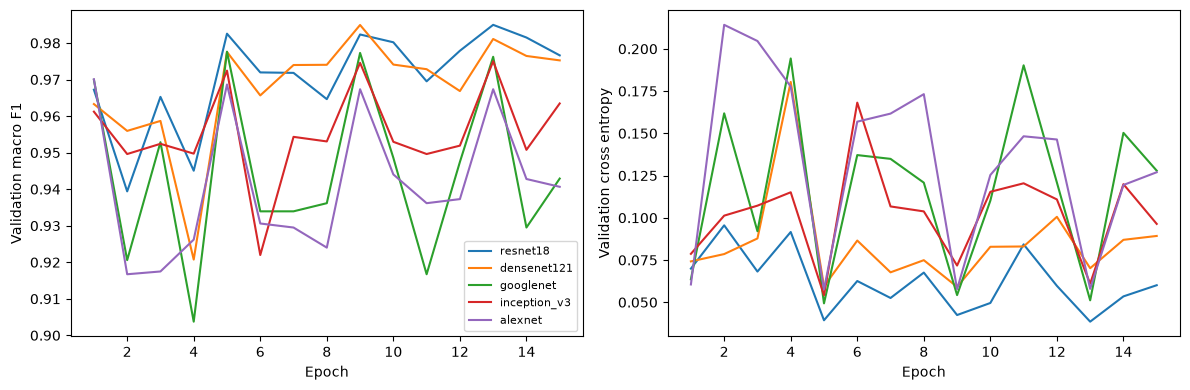

In [5]:
display(pd.DataFrame(summary['validation']['epoch_validation_ensembles']).T[keys].round(4))
print('Selected validation ensemble:',summary['validation']['selected_validation_ensemble'])
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(12,4))
for n in MODEL_NAMES:
    h=json.loads((OUT/f'{n}_history.json').read_text())
    axs[0].plot([a['epoch'] for a in h],[a['validation_metrics']['macro_f1'] for a in h],label=n)
    axs[1].plot([a['epoch'] for a in h],[a['validation_loss'] for a in h],label=n)
axs[0].set(xlabel='Epoch',ylabel='Validation macro F1');axs[1].set(xlabel='Epoch',ylabel='Validation cross entropy')
axs[0].legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'validation_curves.png',dpi=150);plt.show()


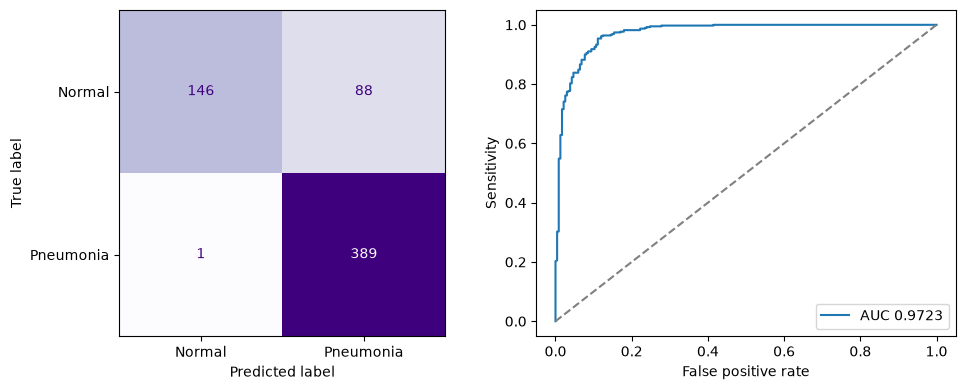

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay,roc_curve
split=json.loads((EXP/'split.json').read_text());y=np.array([r['label'] for r in split['test_records']])
p=np.stack([np.load(OUT/f'{n}_test_probabilities.npy') for n in MODEL_NAMES])
fig,axs=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay(np.array(summary['metrics']['confusion_matrix']),display_labels=['Normal','Pneumonia']).plot(ax=axs[0],colorbar=False,cmap='Purples')
fpr,tpr,_=roc_curve(y,p.mean(0));axs[1].plot(fpr,tpr,label=f"AUC {summary['metrics']['auc']:.4f}")
axs[1].plot([0,1],[0,1],'--',color='gray');axs[1].set(xlabel='False positive rate',ylabel='Sensitivity');axs[1].legend();fig.tight_layout();fig.savefig(OUT/'test_confusion_and_roc.png',dpi=150);plt.show()


## Interpretation and limits

Higher validation than test performance can reflect distribution differences, group proxies or residual leakage, as well as model generalization problems. It does not identify one causal explanation. Cached augmentation, fixed normalization, seed 42, pretrained weight versions, DenseNet's frozen norm5 and unspecified author settings remain differences. One training seed and one hospital do not establish robustness or clinical safety. An ensemble Grad-CAM demo explains a ResNet18 component, not the whole vote or pneumonia lesions.

The revised M3 proposal combines lung cropping with a pretrained small ViT. Cropping remains the primary handout hypothesis, and ViT is a separate extension. Four matched full/crop and CNN-only/CNN-plus-ViT comparisons will separate their effects. Neither improvement has run. Predicted gains remain hypotheses, not measured results. JEPA and mixup remain optional later work. We make no state-of-the-art claim.

# M3 lung cropping and CNN ViT proposal

## Revision before implementation

Revised5 October2026. The proposed final system now combines lung cropping and a pretrained small ViT with the five CNNs. Neither improvement has been implemented or measured. The ongoing15-epoch run remains the full-image CNN baseline. This revision supersedes the crop-only scope below, while retaining its crop mechanism, safeguards and numerical predictions.

The handout asks for one primary change. Cropping remains that primary hypothesis and the transformer is an explicit second extension. We will not describe their joint implementation as a one-variable experiment.

The final candidate is: a fixed lung segmenter supplies both lung masks; crop their union bounding box with10% margin before resizing original-resolution pixels to224; run the five CNNs and an ImageNet-pretrained DeiT-Tiny candidate; combine pneumonia probabilities. DeiT-Tiny is a resource-bounded choice, not an exact P9 DeiT-Base reproduction.

| Experiment | Input | Classifiers |
| --- | --- | --- |
| A | Full X-ray | Five CNNs, probability aggregation |
| B | Lung crop | Five CNNs, probability aggregation |
| C | Full X-ray | Five CNNs plus pretrained ViT |
| D | Lung crop | Five CNNs plus pretrained ViT |

B-A isolates cropping. C-A isolates adding ViT. D-B tests ViT on crops. D-C tests cropping in the hybrid. D is our final target, not the only comparison.

Use score=(1-w)*mean(CNN pneumonia probabilities)+w*ViT pneumonia probability. Predeclare w in{0,0.1,0.2,0.3,0.5} and thresholds in{0.4,0.5,0.6}. Select using validation macro F1 subject to the recall safeguard, then AUC, then lower ViT weight. For equal weight/AUC, prefer threshold0.5, then the lower threshold. The CNN-only comparator uses the same probability aggregation and validation threshold-selection process with w=0. Report the original P7 majority-vote reconstruction separately. Changing aggregation must not be mistaken for a ViT benefit.

Retain the crop prediction below for B-A. For adding ViT under a matched aggregation protocol, predict macro F1 +0.01 to +0.03 and accuracy +1 to +3 percentage points, with zero or negative gain possible. For D-A, predict macro F1 +0.01 to +0.04 and accuracy0 to +3 points with pneumonia recall no more than2 points lower. These are hypotheses, not measured gains, and are bounded by metric maxima. Crop and ViT gains must not be added together. No macro-F1 gain or a recall loss beyond2 points fails to support the combined hypothesis.

Keep the same deduplicated group split, source images, comparable per-model schedules, CNN trainable boundaries and augmentation across matched conditions. Choose checkpoints, weights and thresholds on validation only, never test. Filename groups remain proxies and the original benchmark test was previously inspected. Report class-specific metrics, paired uncertainty, crop failures and runtime. Begin ViT with a frozen-backbone classifier pilot and consider limited last-block tuning only after memory/time checks. One model at a time, two CPU threads and existing resource guards remain mandatory. No crop/ViT training starts before this M3 proposal is submitted.

CNN-transformer hybrids already exist. JEPA feature transfer and mixup remain optional later experiments, outside the primary four-way comparison. I-JEPA predicts image representations; V-JEPA focuses on video/world modelling. Mixup blends examples and labels and is not LeCun's JEPA method. None supplies new independent clinical evidence.

Sources: [DeiT](https://github.com/facebookresearch/deit), [existing hybrid](https://pmc.ncbi.nlm.nih.gov/articles/PMC10248870/), [I-JEPA](https://github.com/facebookresearch/ijepa), [mixup](https://arxiv.org/abs/1710.09412).

Recorded 5 October 2026. Status: proposed experiment, not implemented or measured.

## Selected baseline

P7: Chouhan et al., A Novel Transfer Learning Based Approach for Pneumonia Detection in Chest X-ray Images, Applied Sciences 10(2), 559, 2020. DOI: https://doi.org/10.3390/app10020559.

Five ImageNet-pretrained CNNs (AlexNet, DenseNet121, InceptionV3, ResNet18 and GoogLeNet) use frozen early feature layers and trainable late blocks/classifiers as specified by the paper's Figures4-8. Three or more pneumonia votes give the final label. Our local five-epoch schedule is a declared resource limit. This replaces the tentative Kermany/InceptionV3 baseline presented in M1 while retaining the change to image region.

## Primary crop hypothesis retained from the earlier proposal

Replace the full image with a lung-focused crop derived from a pretrained chest X-ray lung segmentation model. Use the union of both lung masks, expand its bounding box by a fixed 10% margin, then resize the crop to 224 by 224. Keep the same five classifiers, training schedule, augmentation, split, seed and majority-vote rule in the paired control and crop experiments.

For M4, obtain original-resolution pixels from the verified source shards again and crop BEFORE the initial 224-pixel resize. The current Mac cache contains only the M2 initial resize. Cropping that small cache and enlarging it would not recover lung detail. Process original images one shard at a time rather than storing the entire full-resolution collection. The paired full-image control will use those same source pixels and the same final resize.

Cropping is one input-preprocessing variable. In B versus A, keep the classifier family and aggregation identical. C and D separately introduce the transformer extension stated above. The segmentation model must be fixed and trained on separate data. Failed masks fall back to the full image, with the failure count reported. A crop is a bounding rectangle and can contain non-lung pixels. We do not claim that it removes all shortcuts.

The concrete candidate is TorchXRayVision's pretrained ChestX-Det PSPNet, whose official code exposes Left Lung and Right Lung channels: https://github.com/mlmed/torchxrayvision. Its documentation, source and segmentation demo have been inspected; its weights and crop experiment have not been run here. It outputs 14 anatomy channels at 512 pixels and comes from ChestX-Det, not Kermany. M4 will use its documented preprocessing, apply sigmoid to the output logits as in the official demo, and threshold the left/right lung probabilities at 0.5. Pediatric mask quality remains an explicit limitation.

## Hypothesis and mechanism

Lung-focused cropping may improve the balance between normal-class and pneumonia-class recognition by devoting more of the fixed input resolution to lung tissue and reducing peripheral image variation. It may also remove useful anatomy or fail on pediatric images, so improvement is uncertain.

## Numerical prediction before the experiment

Relative to an identically run full-image control, we predict **macro F1 increases by 0.01 to 0.03**, **normal-class recall (specificity) increases by 2 to 5 percentage points**, and **ROC AUC changes by 0.00 to +0.02**. We predict pneumonia recall changes within **minus 2 to plus 2 percentage points**, and accuracy within **minus 1 to plus 2 percentage points**. These are reasoned predictions, not results, confidence intervals or a claim of state of the art.

This updates M1's prediction of less than one percentage point accuracy movement: after changing the base paper, we make macro F1 and specificity the primary expected benefit. We retain the possibility of little or no accuracy improvement. No crop experiment has been run for M2/M3.

## M4 evaluation design

1. Use the fixed deduplicated group split from the audited restart or predeclare any justified replacement before the new runs. Document normal-image identifier ambiguity. Preserve the original624-image benchmark partition for paired final evaluation, but disclose it was inspected earlier and is not a blind external holdout. Also report unique-image sensitivity analysis. Do not tune on test scores.
2. Re-run the full-image control under that split. The M2 paper-comparison score is not interchangeable with this new protocol's control score.
3. Run A/B/C/D with matching settings and the probability-aggregation controls specified in the revision. Select checkpoints by validation macro F1, then AUC and earlier epoch. The original three-of-five vote remains a separately reported reconstruction, not the aggregation control for judging ViT. Select any proposed weights/thresholds using validation only, then evaluate all declared conditions on test.
4. Repeat paired runs for seeds 42, 43 and 44 if resources allow. Report the seed results and paired bootstrap intervals for metric differences. Do not infer significance from overlap of separate intervals.
5. Report accuracy, pneumonia sensitivity, specificity, precision, both class F1 scores, macro F1, AUC and confusion matrices. Include five to ten errors and segmentation failures.
6. Optional diagnostic ablation: apply the fixed crop at test time only to the full-image baseline. This is a distribution-shift test, not the main treatment. A peripheral-only stress test cannot by itself prove shortcut learning.

Grad-CAM examples can support qualitative discussion for individual CNNs. Heatmap overlap with a lung mask measures anatomical concentration, not correct lesion localization, clinical correctness or causal reasoning. There are no lesion annotations here.

## What would refute the prediction

No macro-F1 gain, substantially worse pneumonia recall, or a crop effect indistinguishable from zero across paired seeds would fail to support the hypothesis. We will report the measured outcome even if cropping hurts. The assignment explicitly allows a wrong prediction when reasoning and analysis are sound.

## Scope

This is a student research-reproduction project on a single-center pediatric benchmark. We make no clinical deployment claim and no novelty or state-of-the-art claim. M3 ends with this proposal and the report introduction. Implementation and ablations belong to M4 after submitting this hypothesis.
